In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Matplotlib is building the font cache; this may take a moment.


In [2]:
df = pd.read_csv('../data/healthcare-dataset-stroke-data.csv')
print("Shape:", df.shape)
print("\nColumn types:\n", df.dtypes)
print("\nFirst 5 rows:")
df.head()

Shape: (5110, 12)

Column types:
 id                     int64
gender                   str
age                  float64
hypertension           int64
heart_disease          int64
ever_married             str
work_type                str
Residence_type           str
avg_glucose_level    float64
bmi                  float64
smoking_status           str
stroke                 int64
dtype: object

First 5 rows:


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [3]:
# Shape and basic info
print("Shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
print("\nTarget distribution:\n", df['stroke'].value_counts())
print("\nTarget distribution (%):\n", df['stroke'].value_counts(normalize=True).round(3) * 100)
print("\nNumerical summary:")
df.describe()

Shape: (5110, 12)

Missing values:
 id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

Target distribution:
 stroke
0    4861
1     249
Name: count, dtype: int64

Target distribution (%):
 stroke
0    95.1
1     4.9
Name: proportion, dtype: float64

Numerical summary:


,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


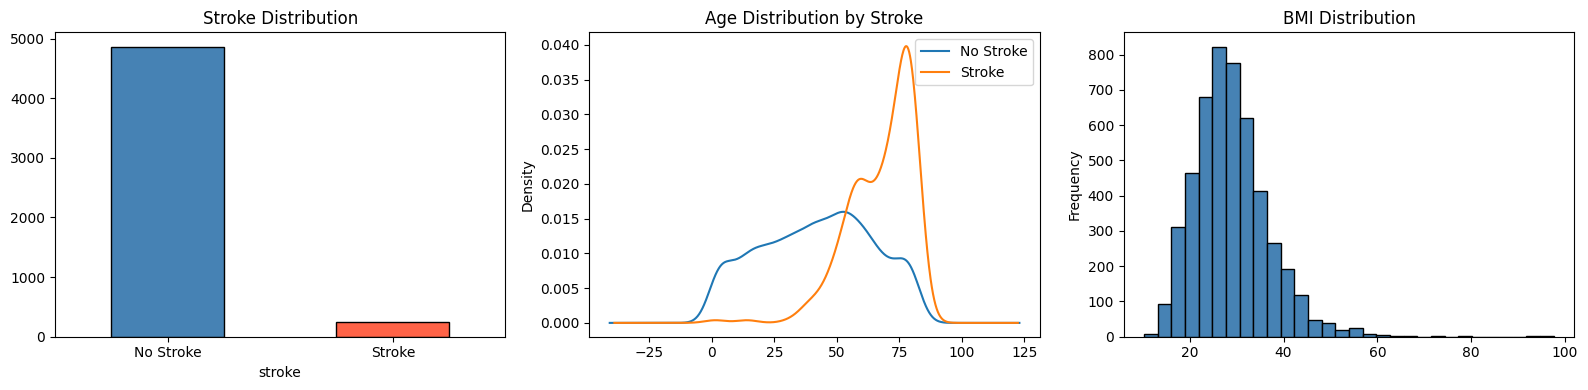

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Target distribution
df['stroke'].value_counts().plot(kind='bar', ax=axes[0], color=['steelblue','tomato'], edgecolor='black')
axes[0].set_title('Stroke Distribution')
axes[0].set_xticklabels(['No Stroke', 'Stroke'], rotation=0)

# Age distribution by stroke
df.groupby('stroke')['age'].plot(kind='kde', ax=axes[1], legend=True)
axes[1].set_title('Age Distribution by Stroke')
axes[1].legend(['No Stroke', 'Stroke'])

# BMI distribution
df['bmi'].plot(kind='hist', bins=30, ax=axes[2], color='steelblue', edgecolor='black')
axes[2].set_title('BMI Distribution')

plt.tight_layout()
plt.show()

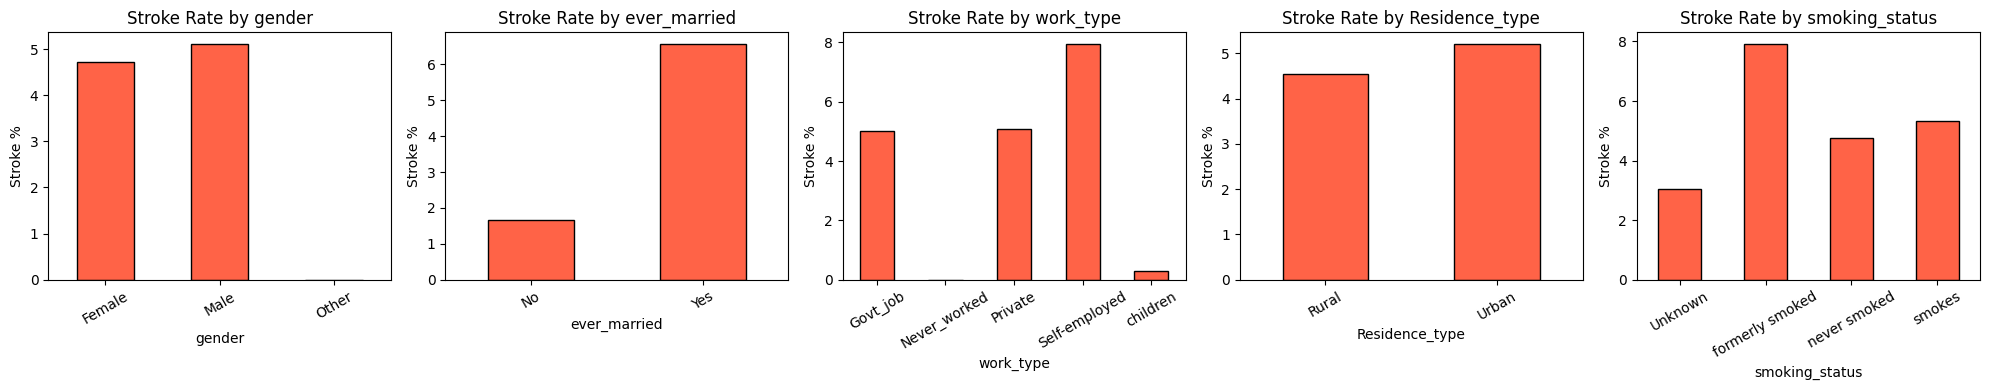

In [5]:
cat_cols = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

fig, axes = plt.subplots(1, len(cat_cols), figsize=(20, 4))

for i, col in enumerate(cat_cols):
    stroke_rate = df.groupby(col)['stroke'].mean() * 100
    stroke_rate.plot(kind='bar', ax=axes[i], color='tomato', edgecolor='black')
    axes[i].set_title(f'Stroke Rate by {col}')
    axes[i].set_ylabel('Stroke %')
    axes[i].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()